# 27 Oct — Visible mirror: local dent to global curvature

Compare the **same mirror without surface error**, the true imperfect mirror, and the image reconstructed from Zernike coefficients. This version starts at **550 nm visible light**. The uniform complex field reflectance is tunable.

**Run All** once. Edit C02 for a reproducible case; use C07 for sliders and **Compute**. Mathematical/plotting helpers are in [mirror_dent_optics.py](mirror_dent_optics.py). All verification and numerical checks are in [optics_validation.ipynb](optics_validation.ipynb), keeping this notebook focused on the experiment. Results include saved figures, coefficients and data.


## M01 — The model and the curved-mirror limit

A height error $h$ is measured relative to an otherwise ideal focusing mirror, with positive height toward incident space. Reflection gives $W=-2h\cos i$. Define a local Gaussian and a shallow global bow:

$$h_{\rm local}=-d e^{-\rho^2/F},\qquad h_{\rm global}=-d(1-\rho^2),\qquad
h=(1-\gamma)h_{\rm local}+\gamma h_{\rm global},\quad0\le\gamma\le1.$$

$\gamma=0$ is a local dent; $\gamma=1$ is global quadratic curvature. At the centred circular default, both have centre depth $d$. $F=0.10$ puts the local Gaussian's $1/e$ contour inside 10% of mirror area; tails continue beyond it. Position/ellipticity controls apply to the local component. The global bow stays centred and circular.

**Yes: a broad shallow dent can be described mainly as curvature.** For $F\gg1$,

$$h_{\rm local}\simeq-d+\frac dF\rho^2-\frac{d}{2F^2}\rho^4+\cdots.$$

After removing piston, the quadratic term dominates. At fixed Gaussian depth, that curvature decreases as $1/F$. The separate global-bow control lets you set a global sag without this decrease. Its shallow radius is approximately $R=a^2/(2d)$, where $a$ is the pupil radius and all lengths use consistent units.

For a pure global bow,

$$W=2d\cos i(1-\rho^2)=d\cos i\,Z_0^0-\frac{d\cos i}{\sqrt3}Z_2^0.$$

It therefore adds piston and **defocus**. A curved mirror does not automatically mean primary spherical aberration. Exact spherical surfaces have higher-order corrections; this model isolates the shallow quadratic limit. It is a scalar, paraxial, phase-screen model, with the mirror error mapped to the exit pupil.


In [1]:
# C01 — Load the shared model and plotting tools.
from pathlib import Path
import sys
BASE_DIR=Path.cwd()
if not (BASE_DIR/'mirror_dent_optics.py').exists():
    candidate=BASE_DIR/'Discussion Series'/'27 Oct'
    if candidate.exists():BASE_DIR=candidate
sys.path.insert(0,str(BASE_DIR))
from dataclasses import replace
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython import get_ipython
from IPython.display import display,Markdown
if get_ipython() is not None:get_ipython().run_line_magic('matplotlib','inline')
import mirror_dent_optics as optics


## M02 — Editable parameters and complex reflectance

For $r=\eta e^{i\psi}$,

$$P=A\,r\,\exp[2\pi i(W+d_fZ_2^0)/\lambda_0],\qquad I=|\mathcal F\{P\}|^2.$$

Uniform $\eta$ changes brightness by $\eta^2$; uniform $\psi$ is a global phase and does not change an isolated intensity image. The notebook keeps this brightness change: intensities use one **unit-reflector, in-focus** normalization. “Ideal” means no surface error, with the **same** pupil, illumination, wavelength, complex reflectance and chosen focus.

| Parameter | Meaning / units |
|---|---|
| wavelength_nm | 380–780 nm; default 550 nm |
| depth_nm | Signed surface depth/sag in nm; positive means a depression, zero removes the error |
| global_curvature | $\gamma$: 0 local Gaussian, 1 global quadratic bow |
| area_fraction | Gaussian width ratio $F$; above 1 the parent Gaussian extends beyond the mirror |
| reflection_magnitude, reflection_phase_deg | Field $|r|\in[0,1]$ and phase in degrees; power reflectance is $|r|^2$ |
| mirror_diameter_mm, focal_length_mm | Physical scale and paraxial NA; keep NA ≤ 0.2 |
| n_max | Maximum integer radial degree, not a Noll/Fringe index |
| added_defocus_nm | Common added coefficient of normalized $Z_2^0$, in OPD nm |
| center_u, center_v, aspect_ratio, orientation_deg | Optional local dent displacement/ellipse in pupil-radius units and degrees |
| noise_rms_nm, seed | Optional synthetic OPD metrology noise and reproducible seed |
| n_pupil, fft_pad | Pupil resolution and image interpolation by zero padding |
| quad_radial, quad_angular | Independent coefficient-integration quadrature |
| scene_kind, point_separation_s, bar_width_s, bar_gap_s | Incoherent object pattern; $s=\mathrm{NA}\,x/\lambda_0$ |

Other aperture/illumination and object options remain available through the documented Parameters class. Change C02, then rerun C03–C08. Increase pupil samples for narrow/deep errors; padding alone adds no surface information.


In [2]:
# C02 — EDIT the baseline here. Positive depth is a dent; all length units are explicit.
P=optics.Parameters(
    wavelength_nm=550.0, depth_nm=120.0, area_fraction=0.10,
    global_curvature=0.0,
    reflection_magnitude=0.95, reflection_phase_deg=135.0,
    mirror_diameter_mm=20.0, focal_length_mm=200.0,
    n_max=8, added_defocus_nm=0.0,
    center_u=0.0, center_v=0.0, aspect_ratio=1.0, orientation_deg=0.0,
    noise_rms_nm=0.0, seed=27,
    n_pupil=256, fft_pad=4, quad_radial=64, quad_angular=128,
    scene_kind='mixed', point_separation_s=1.0, bar_width_s=0.5, bar_gap_s=0.5,
)
ORDERS=[0,2,4,6,8,10,12,16,20]  # Integer radial degrees for C06.
SAVE=True


## M03 — Surface error and reconstructed wavefront

Fit the **OPD**, not the surface height: $c_n^m=\langle WZ_n^m\rangle$ on a clear, uniformly weighted disk, where $\langle f\rangle=\pi^{-1}\int_0^{2\pi}\int_0^1 f(\rho,\theta)\rho\,d\rho\,d\theta$. The real basis has unit mean square, $m>0$ cosine and $m<0$ sine. Reconstruct $\widehat W=\sum c_n^mZ_n^m$, then recompute the diffraction image. Piston remains in the coefficient list but is removed from displayed wavefront RMS/maps. The same optional focus is applied to all comparison images.

For an obscured pupil, the implementation instead uses weighted least squares in the same full-disk basis; those coefficients are no longer independent RMS contributions.


Wavelength 550 nm; reflectance r=-0.6718+0.6718j; power=0.9025
1 image unit = 1.1e+04 nm; OPD reconstruction RMS = 4.2977 nm


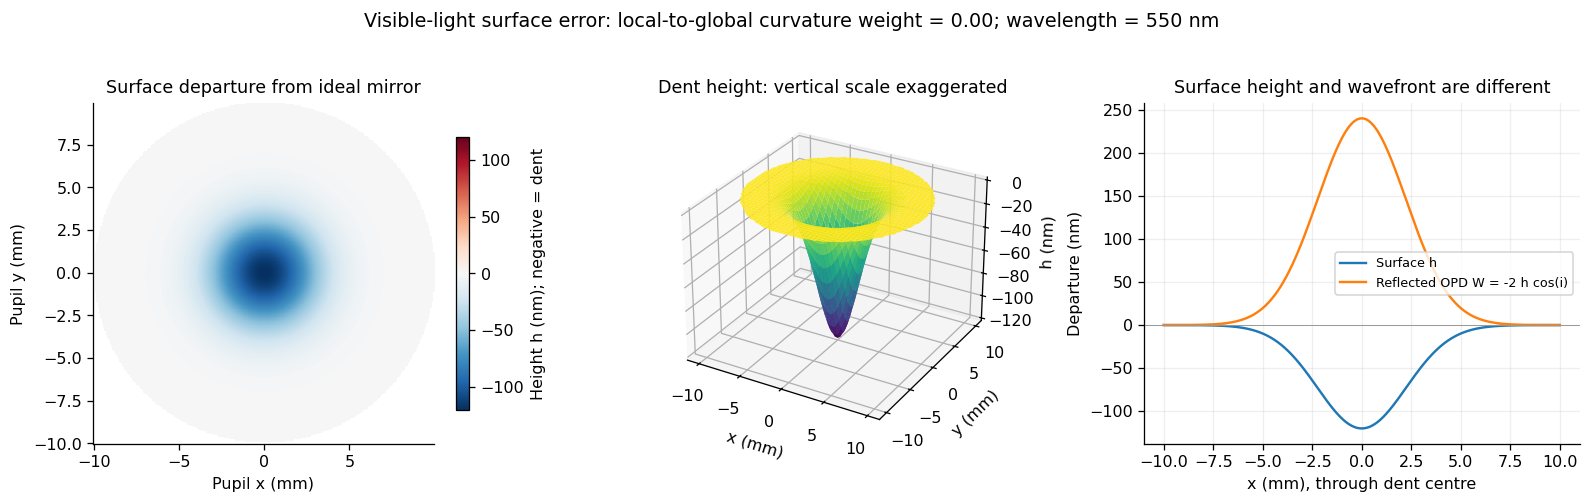

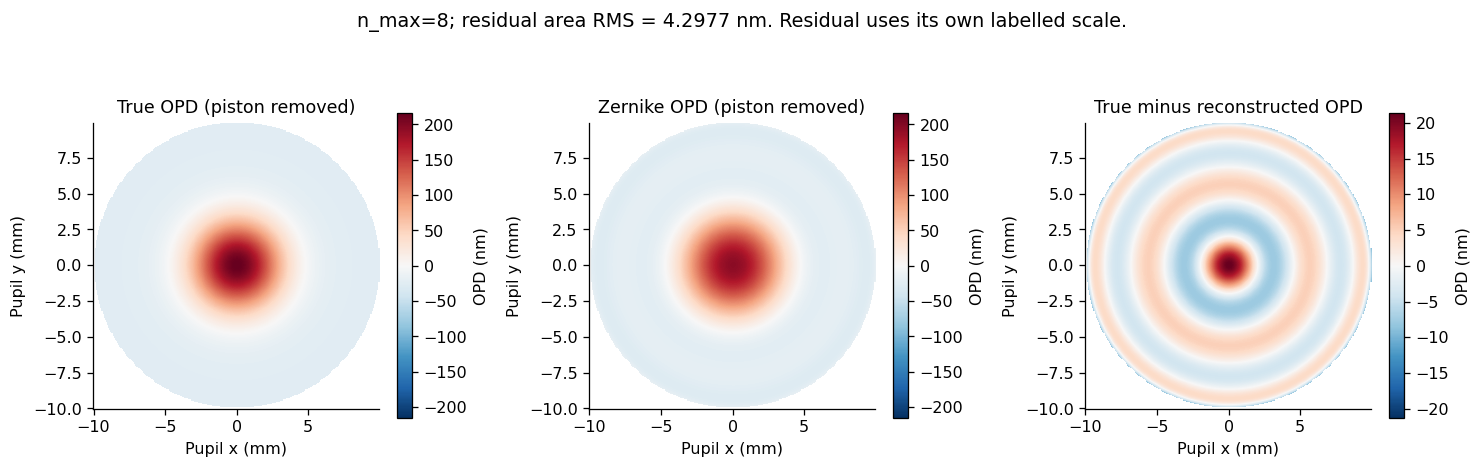

In [3]:
# C03 — Compute the case; inspect mirror height and wavefront reconstruction.
CASE=optics.build_study(P)
FIGURES={}
print(f'Wavelength {P.wavelength_nm:g} nm; reflectance r={CASE["reflection"]:.4g}; power={abs(CASE["reflection"])**2:.4f}')
print(f'1 image unit = {P.image_unit_nm:.4g} nm; OPD reconstruction RMS = {CASE["fit"]["residual_rms_nm"]:.5g} nm')
for name,make in [('01_surface',optics.plot_geometry),('02_wavefront',optics.plot_wavefronts)]:
    FIGURES[name]=make(CASE);display(FIGURES[name]);plt.close(FIGURES[name])


## M04 — Which Zernike terms appear?

A centred circular dent has only $m=0$, even-$n$ terms. A localized error needs several radial/spherical orders; the global-bow endpoint has only piston and defocus. Displacing or stretching the local component introduces angular modes. Coefficients below are in **OPD nm**; roundoff-sized angular entries in a symmetric case are not physical aberrations.


,n,m,mode,coefficient_nm,coefficient_waves
4,2,0,Defocus,-3.325764e+01,-6.046844e-02
12,4,0,Balanced primary spherical,2.790194e+01,5.073080e-02
0,0,0,Piston,2.399891e+01,4.363438e-02
24,6,0,Balanced secondary spherical,-1.778787e+01,-3.234158e-02
40,8,0,Higher radial / spherical family,9.197015e+00,1.672185e-02
32,7,1,Higher angular mode,1.268691e-15,2.306711e-18
18,5,1,Higher angular mode,-1.219122e-15,-2.216586e-18
8,3,1,Balanced coma,1.197864e-15,2.177935e-18
23,6,-2,Higher angular mode,-1.097460e-15,-1.995382e-18
33,7,3,Higher angular mode,-1.033051e-15,-1.878275e-18


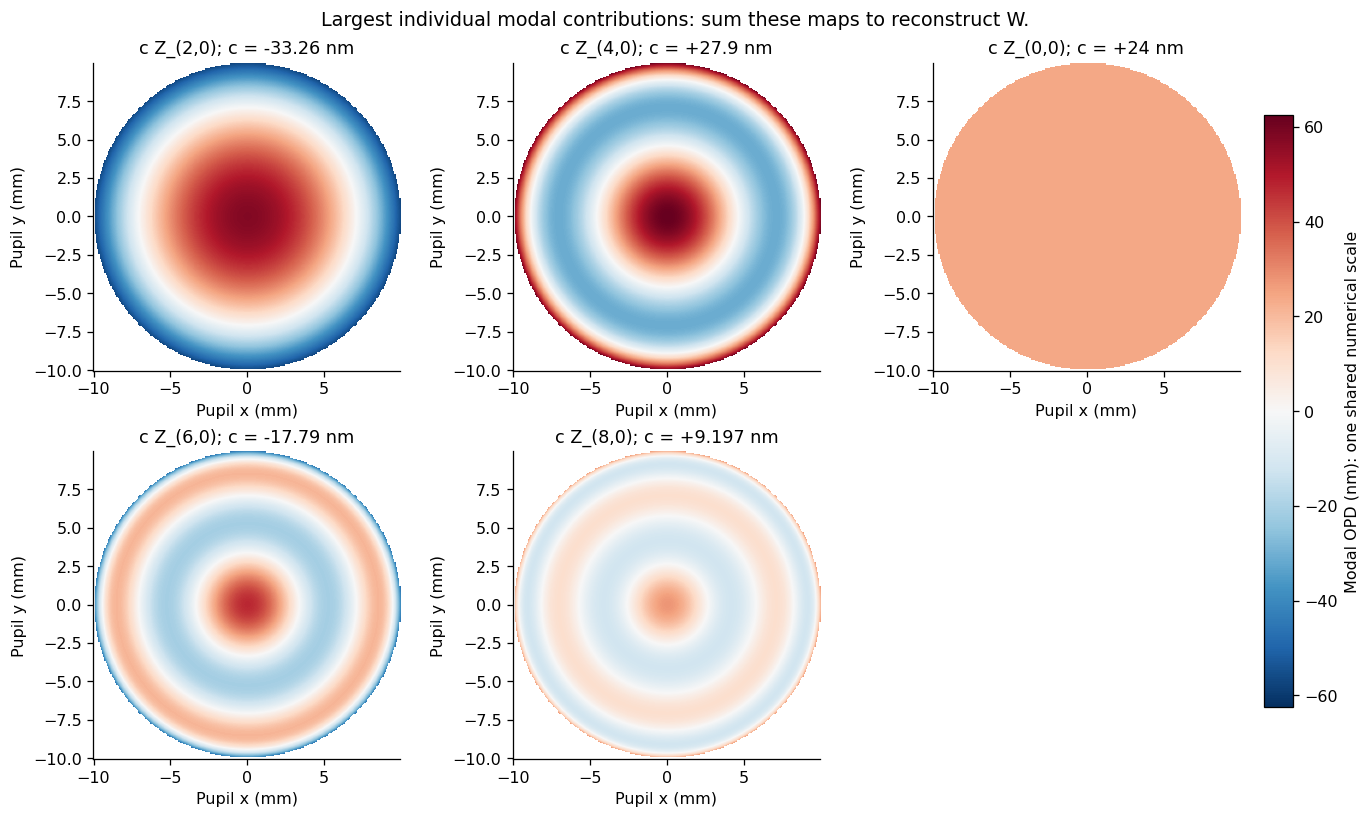

In [4]:
# C04 — Largest coefficients and their pupil-map contributions.
display(CASE['coefficients'].sort_values('coefficient_nm',key=abs,ascending=False).head(12))
FIGURES['03_modes']=optics.plot_modal_contributions(CASE)
display(FIGURES['03_modes']);plt.close(FIGURES['03_modes'])


## M05 — Point images and a simple incoherent object

All point images share one incident-light intensity scale. Extended-object images use $I_{\rm object}*\mathrm{PSF}_{\rm unit\ energy}$ multiplied by the reflected-power fraction, so changing $|r|$ changes brightness. A local phase error redistributes light; it does not itself absorb it. For global curvature, a focus change can remove the quadratic error; the RMS-refocus option is explicit in C07.


,on_axis_ratio,sampled_peak_ratio,energy_in_0p61,throughput
case,,,,
Ideal,0.902500,0.902500,0.838064,0.9025
True dent,0.700553,0.700553,0.600599,0.9025
Zernike reconstruction,0.695407,0.695407,0.597247,0.9025


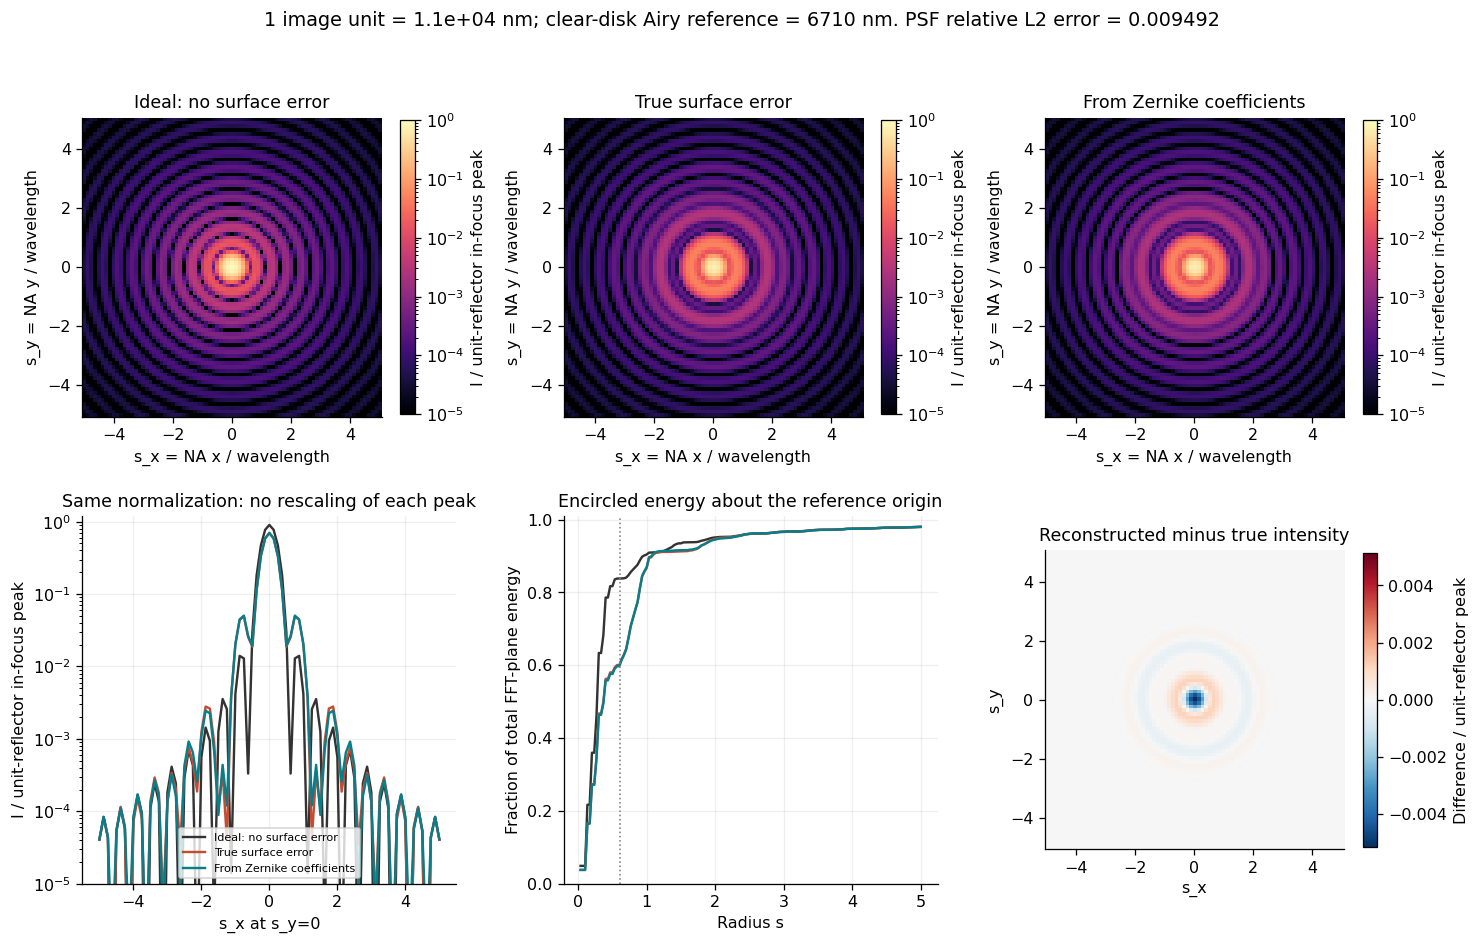

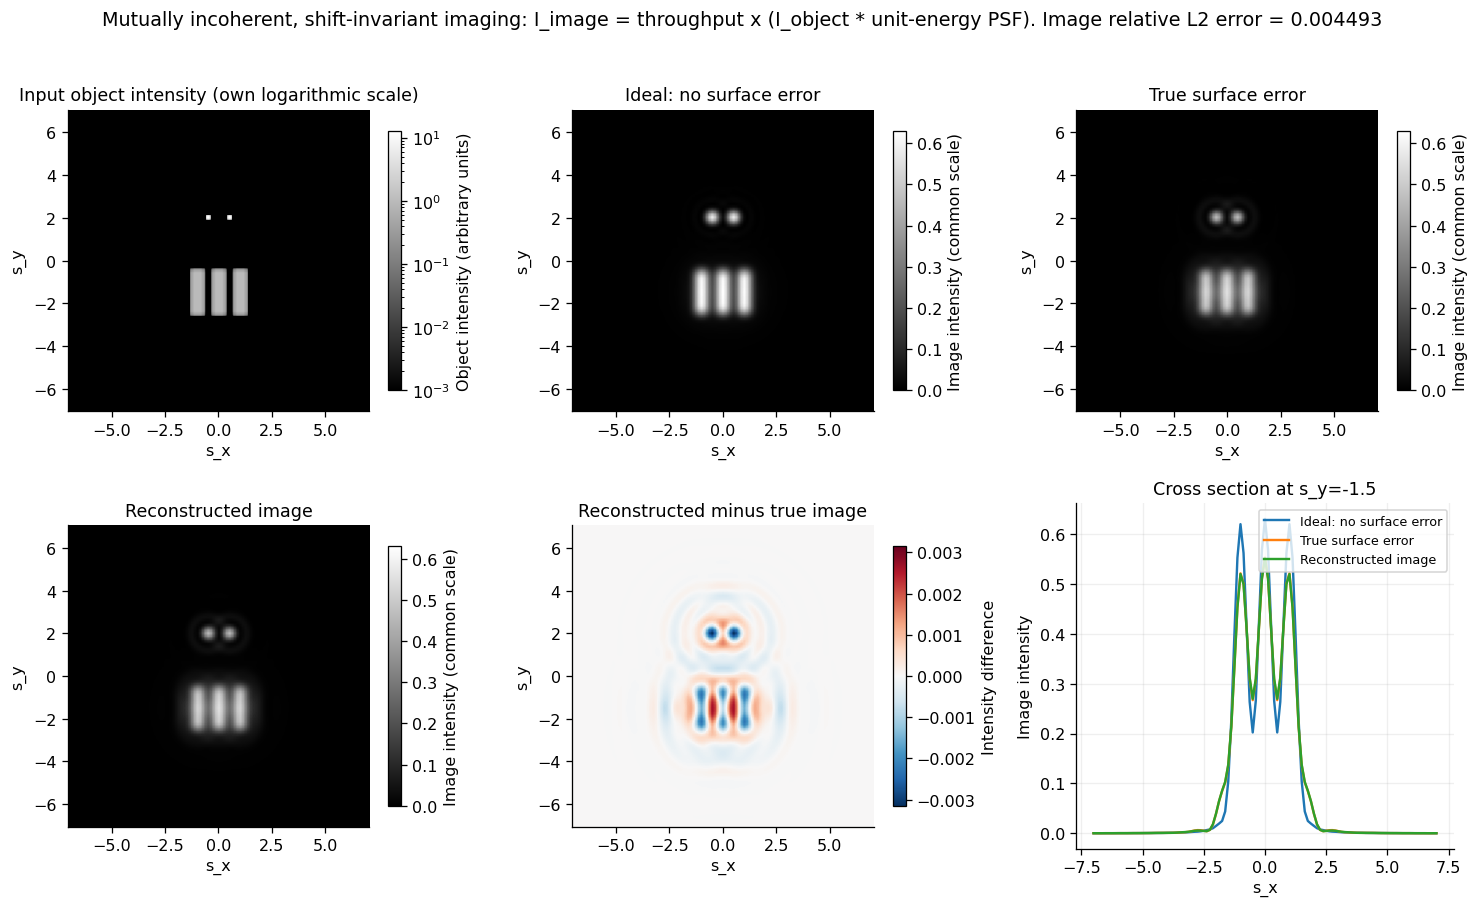

In [5]:
# C05 — Compare ideal (no surface error), true, and Zernike-reconstructed images.
display(CASE['metrics'].drop(columns='discrete_total_intensity').round(6))
for name,make in [('04_point_images',optics.plot_psfs),('05_object_images',optics.plot_scene)]:
    FIGURES[name]=make(CASE);display(FIGURES[name]);plt.close(FIGURES[name])


## M06 — Integer-order convergence

A finite expansion approximates the same known error. Increase the maximum integer degree and compare both wavefront RMS and image error. Wavefront convergence does not require an image metric to move monotonically. The axes use the actual integer orders. Noise and a restricted or obscured pupil change how coefficients should be interpreted; those checks are in the separate validation notebook.


,n_max,mode_count,residual_rms_nm,psf_relative_L2
0,0,1,48.000545,3.903289e-01
1,2,6,34.611872,2.297290e-01
2,4,15,20.480809,6.376205e-02
3,6,28,10.151617,1.610590e-02
4,8,45,4.297703,9.492208e-03
5,10,66,1.580728,3.503164e-03
6,12,91,0.512515,8.884220e-04
7,16,153,0.038689,2.613725e-05
8,20,231,0.001998,5.638868e-07


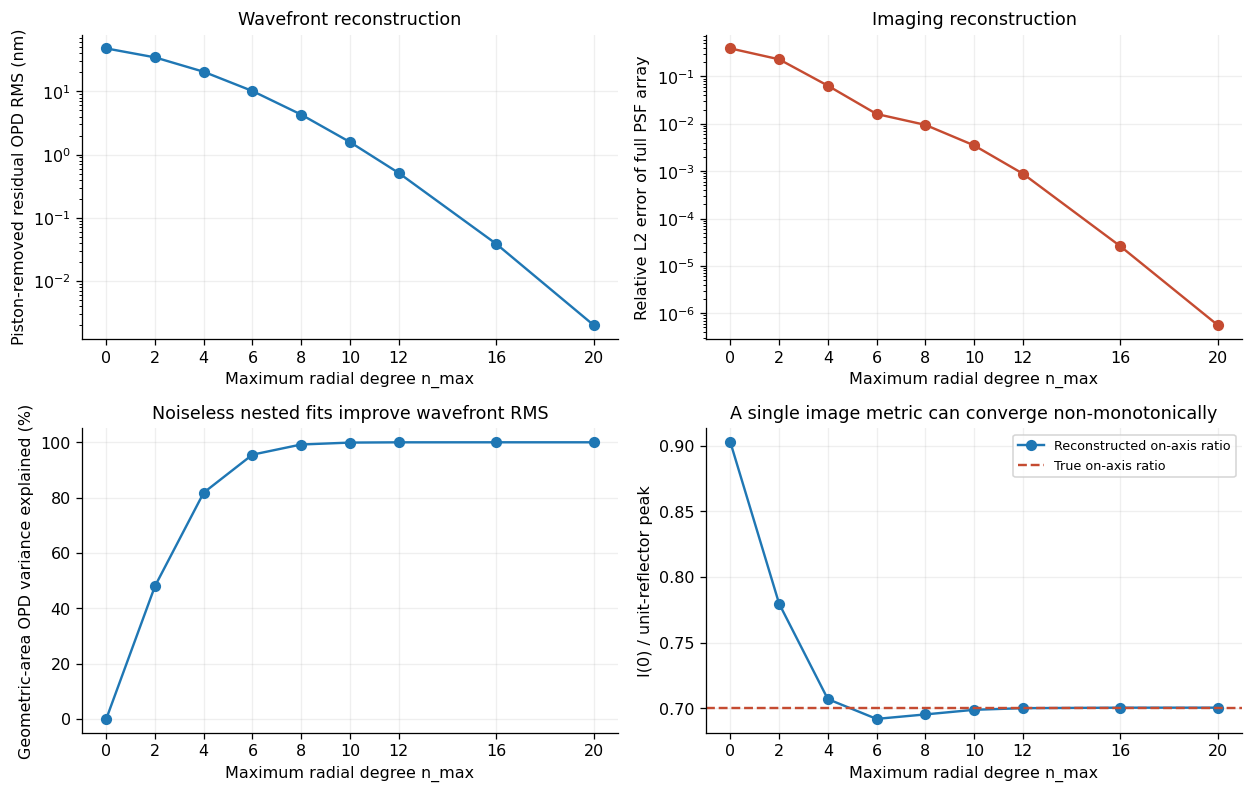

In [6]:
# C06 — The order-convergence experiment (integer ticks only).
CONVERGENCE=optics.convergence_study(P,ORDERS)
display(CONVERGENCE[['n_max','mode_count','residual_rms_nm','psf_relative_L2']])
FIGURES['06_order_convergence']=optics.plot_convergence(CONVERGENCE,CASE)
display(FIGURES['06_order_convergence']);plt.close(FIGURES['06_order_convergence'])


## M07 — Interactive controls

Move **Local dent → global bow** from 0 to 1, vary the Gaussian width, and inspect the change from several radial orders to defocus. Change the reflection phase while holding $|r|$ fixed: intensity should stay unchanged. The refocus checkbox uses the known simulated wavefront to minimize geometric-area RMS; it is not an optimization of every image metric. All three comparisons still use the same chosen focus.


In [7]:
# C07 — Live controls: change values, then click Compute selected case.
DASHBOARD=optics.make_dashboard(P)
display(DASHBOARD['ui'])


## M08 — Save or rerun

C08 saves the baseline under results/visible. To save a successful interactive case, call <code>optics.export_study(DASHBOARD['state']['study'], directory=BASE_DIR/'results'/'visible_interactive')</code>. Saved output is viewable without a kernel; live controls require a widget-enabled Jupyter/VS Code frontend and a running Python kernel.

The Zernike convention follows Chapter 7 of the local [textbook](../../aberration%20budget%20paper/aberration_budget_textbook.pdf). The separate [validation notebook](optics_validation.ipynb) contains analytic checks, quadrature/grid refinement and widget callback tests.


In [8]:
# C08 — Optional baseline export. Choose another directory to retain another case.
if SAVE:optics.export_study(CASE,CONVERGENCE,FIGURES,BASE_DIR/'results'/'visible')


Exported 18 files to C:\Users\fxl04\Desktop\Prof. Wong Grp Papers\Discussion Series\27 Oct\results\visible
